# Module 1 · Partie 4 : Sélection de variables (feature selection)

> Cours *Analyse multivariée 2 : Data Mining & Machine Learning* (Prof. H. Soyeurt, ULiège Gembloux Agro-Bio Tech).
> Sources de cette partie : syllabus `module1.pdf` §3.3, slides *Linear, Ridge, Lasso regressions* (diapositive « Feature selection – Variable selection »), résolution `resolution_lactoferrin_2425` §7 et §8, `Homework1/homework1.R` étape 7.

**Objectifs d'apprentissage**

À la fin de ce notebook, tu sauras :

1. expliquer **pourquoi** il faut sélectionner des variables quand elles sont nombreuses et colinéaires ;
2. construire **automatiquement une formule de régression** avec `paste0()` et `as.formula()` ;
3. tester **toutes les combinaisons** de variables avec `olsrr::ols_step_all_possible()` et classer les modèles selon le R², le R² ajusté, l'AIC ou le BIC ;
4. réaliser une sélection **backward**, **forward** et **stepwise** avec `MASS::stepAIC()` et **lire sa trace** ;
5. comparer les méthodes et connaître leurs limites ;
6. quantifier la **contribution relative** de chaque variable avec le package `relaimpo` (lmg, last, first, pratt + bootstrap).

**Prérequis** : parties 2 (régression univariée, analyse des résidus) et 3 (régression multivariée, colinéarité).

**Sommaire**

- 4.0 Mise en place : données et 10 variables les plus corrélées
- 4.1 Pourquoi sélectionner des variables ?
- 4.2 Construire une formule automatiquement (`paste0`, `as.formula`)
- 4.3 Tester toutes les combinaisons (`ols_step_all_possible`)
- 4.4 Les critères de choix : R², R² ajusté, AIC, BIC
- 4.5 Sélection backward (`stepAIC`)
- 4.6 Sélection forward
- 4.7 Sélection stepwise
- 4.8 Comparaison et commentaires finaux
- 4.9 Outils d'interprétation : importance relative (`relaimpo`)
- 4.10 Compléments : `step()` et `leaps::regsubsets()`
- Récapitulatif

## 4.0 Mise en place : données et 10 variables les plus corrélées

Ce notebook est **autonome** : on recharge les données et on reconstruit les objets de la partie 3.

Rappel (partie 3) :
- `lactoferrin.csv` : 178 échantillons de lait × 1062 colonnes (V1 = identifiant, V2:V1061 = spectre MIR à 1060 points, V1062 = teneur en lactoferrine en mg/L) ;
- on a retenu les **10 points spectraux les plus corrélés** (en valeur absolue) avec la lactoferrine ;
- la lactoferrine est modélisée en **log10** car c'est cette transformation qui rend les résidus normaux (partie 2).

In [1]:
# Packages utilisés dans ce notebook
suppressPackageStartupMessages({
  library(olsrr)     # ols_step_all_possible() : toutes les combinaisons
  library(MASS)      # stepAIC() : backward / forward / stepwise
  library(knitr)     # kable() : tableaux propres
  library(relaimpo)  # calc.relimp() : importance relative des variables
})
options(repr.plot.width = 10, repr.plot.height = 6)  # taille des figures (propre à Jupyter)

# setwd("chemin/vers/Module1")  # inutile en Jupyter : le dossier courant est celui du notebook
lactoferrin <- read.table(file = "../lactoferrin.csv", sep = ";")
dim(lactoferrin)

[1]  178 1062

In [2]:
# Corrélation de chaque point spectral avec la lactoferrine (méthode du cours)
correlation <- cor(lactoferrin[, 2:1062])        # matrice 1061 x 1061 (spectre + lactoferrine)
correlation <- correlation[1:1060, 1061]          # on garde la colonne "lactoferrine" pour les 1060 points spectraux
ordercorrelation <- order(abs(correlation))       # rangs du |r| le plus faible au plus fort

# Les 10 features les plus corrélées (+1 car la colonne 1 = identifiant)
x <- as.matrix(lactoferrin[, ordercorrelation[1051:1060] + 1])
y <- as.matrix(lactoferrin[, 1062])               # lactoferrine (mg/L), forme matrice 1 colonne

kable(t(correlation[ordercorrelation[1051:1060]]), digits = 2)



|  V608|  V679| V716| V710| V209| V715| V711| V714| V712| V713|
|-----:|-----:|----:|----:|----:|----:|----:|----:|----:|----:|
| -0.23| -0.23| 0.27|  0.3| 0.32| 0.36| 0.44| 0.46| 0.51| 0.51|

On retrouve exactement les 10 points de la résolution : **V608, V679, V716, V710, V209, V715, V711, V714, V712, V713**.
Dans la suite, `x[, 1]` = V608, …, `x[, 10]` = V713 (la variable la plus corrélée).

> **Attention** : l'ordre des colonnes de `x` est l'ordre **croissant** de |r|. Donc `x[, 10]` est la plus corrélée et `x[, 1]` la moins corrélée des 10. Garde ce tableau de correspondance sous la main pour interpréter les résultats.

In [3]:
# Tableau de correspondance indice <-> nom de la variable
data.frame(indice = paste0("x[, ", 1:10, "]"), variable = colnames(x),
           r = round(correlation[ordercorrelation[1051:1060]], 3))

,indice,variable,r
,<chr>,<chr>,<dbl>
V608,"x[, 1]",V608,-0.226
V679,"x[, 2]",V679,-0.227
V716,"x[, 3]",V716,0.267
V710,"x[, 4]",V710,0.303
V209,"x[, 5]",V209,0.318
V715,"x[, 6]",V715,0.364
V711,"x[, 7]",V711,0.438
V714,"x[, 8]",V714,0.463
V712,"x[, 9]",V712,0.507


## 4.1 Pourquoi sélectionner des variables ?

Dans la partie 3, le modèle multivarié `reg2b` (log10(y) ~ 10 features) donnait R² = 0.40, mais **aucun coefficient n'était significatif**. La raison est la **colinéarité** : les points spectraux adjacents sont très corrélés entre eux (r jusqu'à 0.99) et portent donc la *même* information.

Le syllabus (§3.3) résume la démarche :

1. **Première sélection** des variables les plus discriminantes :
   - si $y$ et les $x$ sont **quantitatives** → le coefficient de corrélation $r$ suffit (*c'est ce qu'on a fait pour choisir les 10 features*) ;
   - cette pratique **ne tient pas compte des relations non linéaires** ;
   - si $y$ est quantitative et les $x$ **qualitatives** → analyse de la variance (ANOVA) à un ou plusieurs critères (cours de Statistiques appliquées STAT2004/2005).
2. Les variables ainsi pré-sélectionnées peuvent être **corrélées entre elles** → problèmes de colinéarité dans la régression.
3. On utilise donc des **méthodes de sélection** à partir d'un ensemble de variables : **Backward, Forward et Stepwise** (vues en STAT2005 et en *Analyse multivariée 1*), ou on teste **toutes les combinaisons**.

> **Définition** : la **sélection de variables** (*feature selection*) consiste à choisir un sous-ensemble des variables explicatives qui donne un modèle **performant et parcimonieux** (le moins de variables possible pour une bonne prédiction). Un modèle parcimonieux généralise mieux (moins d'overfitting) et est plus facile à interpréter.

La slide « Feature selection – Variable selection » classe les méthodes en deux familles :

| Famille | Méthodes | Où dans le cours ? |
|---|---|---|
| Régressions pénalisées | **Lasso**, **Elastic-Net** | partie 6 |
| Autres méthodes | **Stepwise**, **Backward**, **Forward** | ce notebook (et AM1 « Exploration de données ») |

### Exercice 4.1 : combien de modèles possibles ?

Avec $p$ variables candidates, chaque variable est soit dans le modèle, soit absente. Combien de modèles **non vides** peut-on construire avec $p = 10$ ? Et avec les $p = 1060$ points du spectre entier ? Calcule-le en R.

In [4]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
p <- 10
2^p - 1          # 1023 modèles non vides
2^1060 - 1       # Inf pour R : un nombre gigantesque (~1e319)
```

Chaque variable a 2 états (présente/absente) → $2^p$ sous-ensembles, dont un vide (modèle avec seulement l'intercept) → $2^p - 1$. Avec 10 variables : **1023 modèles** (c'est le nombre annoncé dans la résolution). Avec 1060 variables, c'est impossible à explorer : c'est pour cela qu'on limite d'abord à 10 variables, et qu'on a besoin de méthodes pas-à-pas (backward/forward/stepwise) ou pénalisées (Lasso).

</details>

## 4.2 Construire une formule automatiquement : `paste0()` et `as.formula()`

Pour sélectionner des variables, les fonctions ont besoin d'une **formule** du type `log10(y) ~ x[,1] + x[,2] + ... + x[,10]`. Plutôt que de l'écrire à la main, on la **génère** :

In [5]:
xnam <- paste0("x[,", 1:10, "]")          # vecteur de 10 chaînes : "x[,1]", "x[,2]", ...
xnam
fmla <- as.formula(paste("log10(y) ~ ", paste(xnam, collapse = "+")))
fmla
class(fmla)

[1] "x[,1]"  "x[,2]"  "x[,3]"  "x[,4]"  "x[,5]"  "x[,6]"  "x[,7]"  "x[,8]" 
 [9] "x[,9]"  "x[,10]"

log10(y) ~ x[, 1] + x[, 2] + x[, 3] + x[, 4] + x[, 5] + x[, 6] + 
    x[, 7] + x[, 8] + x[, 9] + x[, 10]

[1] "formula"

> **Fonction R** : `paste()` / `paste0()` — concaténer des chaînes
>
> `paste(..., sep = " ", collapse = NULL)` ; `paste0(...)` = `paste(..., sep = "")`
>
> | Argument | Rôle |
> |---|---|
> | `...` | objets à coller (vectorisés : `paste0("x", 1:3)` → `"x1" "x2" "x3"`) |
> | `sep` | séparateur entre les arguments d'un même élément |
> | `collapse` | si non `NULL`, **fusionne** le vecteur résultat en **une seule** chaîne, séparée par `collapse` |
>
> Renvoie un vecteur de caractères.

> **Fonction R** : `as.formula(chaine)` — transforme une chaîne de caractères en objet `formula` utilisable par `lm()`, `stepAIC()`, etc.
>
> **Généralisation** : pour un data frame `df` avec une réponse `"SAT"` et des colonnes prédictrices `vars` (noms), on écrit
> `as.formula(paste("SAT ~", paste(vars, collapse = " + ")))`. Alternative moderne : `reformulate(vars, response = "SAT")`.

### Exercice 4.2 : formule générique

1. Construis la formule `y ~ x[,1] + x[,2] + x[,3]` (y brut, 3 premières variables) avec `paste0`/`as.formula`.
2. Écris une **fonction** `make_formula(reponse, k)` qui renvoie la formule `reponse ~ x[,1] + ... + x[,k]`. Teste-la avec `make_formula("sqrt(y)", 4)`.

In [6]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
f3 <- as.formula(paste("y ~", paste(paste0("x[,", 1:3, "]"), collapse = " + ")))
f3

make_formula <- function(reponse, k) {
  as.formula(paste(reponse, "~", paste(paste0("x[,", 1:k, "]"), collapse = " + ")))
}
make_formula("sqrt(y)", 4)
```

`paste0` fabrique les noms des variables, `paste(..., collapse = " + ")` les colle en une seule chaîne, et `as.formula` en fait une vraie formule R.

</details>

## 4.3 Tester toutes les combinaisons : `ols_step_all_possible()`

Le package `olsrr` construit **tous les modèles possibles**, de 1 variable jusqu'au nombre de variables disponibles, et calcule pour chacun plusieurs indicateurs de performance (R², R² ajusté, AIC, BIC…).

On part du modèle complet (les 10 variables) :

In [7]:
model <- lm(fmla)                              # modèle complet log10(y) ~ 10 features
selection <- ols_step_all_possible(model)      # 1023 modèles ajustés (quelques secondes)
class(selection)
names(selection)

[1] "ols_step_all_possible"

[1] "result"

> **Attention : version du package.** Dans la résolution (2024-2025), on accédait directement à `selection$n`, `selection$rsquare`… Depuis les versions récentes d'`olsrr` (ici 0.7.0), **les résultats sont rangés dans `selection$result`**. C'est d'ailleurs ce que fait `homework1.R` (« recent versions of olsrr store the performance statistics in selection$result »). Si un vieux script plante sur `selection$n`, c'est la raison.

In [8]:
res <- selection$result
dim(res)          # 1023 modèles x 15 indicateurs
str(res)

[1] 1023   15

'data.frame':	1023 obs. of  15 variables:
 $ mindex    : int  1 2 3 4 5 6 7 8 9 10 ...
 $ n         : int  1 1 1 1 1 1 1 1 1 1 ...
 $ predictors: chr  "x[, 9]" "x[, 10]" "x[, 8]" "x[, 7]" ...
 $ rsquare   : num  0.284 0.284 0.227 0.22 0.135 ...
 $ adjr      : num  0.28 0.28 0.222 0.215 0.131 ...
 $ rmse      : num  0.415 0.415 0.432 0.434 0.456 ...
 $ predrsq   : num  0.268 0.268 0.21 0.203 0.117 ...
 $ cp        : num  25.4 25.5 41.5 43.5 66.9 ...
 $ aic       : num  198 198 212 214 232 ...
 $ sbic      : num  -307 -307 -294 -292 -275 ...
 $ sbc       : num  208 208 222 223 241 ...
 $ msep      : num  31 31 33.5 33.8 37.5 ...
 $ fpe       : num  0.176 0.176 0.19 0.192 0.213 ...
 $ apc       : num  0.732 0.732 0.791 0.798 0.884 ...
 $ hsp       : num  0.000996 0.000996 0.001076 0.001086 0.001203 ...


Les colonnes principales :

| Colonne | Signification |
|---|---|
| `mindex` | numéro du modèle |
| `n` | nombre de variables dans le modèle |
| `predictors` | variables utilisées |
| `rsquare` | R² |
| `adjr` | R² ajusté |
| `rmse` | erreur quadratique moyenne (racine) |
| `predrsq` | R² prédit (calculé par *leave-one-out*, notion du module 2) |
| `cp` | Cp de Mallows |
| `aic` | critère d'information d'Akaike |
| `sbic`, `sbc` | critères bayésiens (SBC = BIC de Schwarz) |
| `msep`, `fpe`, `apc`, `hsp` | autres critères d'erreur de prédiction |

On construit un tableau réduit comme dans la résolution :

In [9]:
table <- data.frame(res$n, res$predictors, res$rsquare, res$adjr, res$aic)
names(table) <- c("n", "predictors", "rsquare", "adjr", "aic")
kable(head(table, 5), digits = 3)                                   # 5 premiers modèles
kable(table[(nrow(table) - 5):nrow(table), ], digits = 3)           # 6 derniers modèles



|  n|predictors | rsquare|  adjr|     aic|
|--:|:----------|-------:|-----:|-------:|
|  1|x[, 9]     |   0.284| 0.280| 198.169|
|  1|x[, 10]    |   0.284| 0.280| 198.252|
|  1|x[, 8]     |   0.227| 0.222| 211.989|
|  1|x[, 7]     |   0.220| 0.215| 213.606|
|  1|x[, 6]     |   0.135| 0.131| 231.817|



|     |  n|predictors                                                             | rsquare|  adjr|     aic|
|:----|--:|:----------------------------------------------------------------------|-------:|-----:|-------:|
|1018 |  9|x[, 2] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]        |   0.397| 0.365| 183.553|
|1019 |  9|x[, 1] x[, 2] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 9] x[, 10]        |   0.397| 0.365| 183.648|
|1020 |  9|x[, 1] x[, 2] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 10]        |   0.397| 0.364| 183.829|
|1021 |  9|x[, 1] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]        |   0.396| 0.364| 183.942|
|1022 |  9|x[, 1] x[, 2] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 9]         |   0.396| 0.363| 184.045|
|1023 | 10|x[, 1] x[, 2] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10] |   0.401| 0.365| 184.574|

**Lecture** : les modèles sont rangés par **nombre de variables** puis par R² décroissant, **pas** par performance globale. Les meilleurs modèles à 1 variable utilisent `x[, 9]` (V712) ou `x[, 10]` (V713) avec R² = 0.284 (c'est le modèle `reg1b` de la partie 2). Le modèle complet (10 variables) a R² = 0.401.

Pour trouver les meilleurs modèles, on **trie par AIC** (le plus bas est le meilleur) :

In [10]:
rankingAIC <- order(table$aic)                 # indices triés par AIC croissant
kable(table[rankingAIC[1:5], ], digits = 3)    # les 5 meilleurs modèles selon l'AIC



|    |  n|predictors                          | rsquare|  adjr|     aic|
|:---|--:|:-----------------------------------|-------:|-----:|-------:|
|386 |  5|x[, 2] x[, 4] x[, 7] x[, 8] x[, 10] |   0.391| 0.374| 177.376|
|387 |  5|x[, 2] x[, 4] x[, 7] x[, 8] x[, 9]  |   0.391| 0.373| 177.569|
|176 |  4|x[, 2] x[, 8] x[, 9] x[, 10]        |   0.383| 0.369| 177.656|
|388 |  5|x[, 2] x[, 4] x[, 6] x[, 7] x[, 9]  |   0.390| 0.372| 177.746|
|389 |  5|x[, 2] x[, 4] x[, 8] x[, 9] x[, 10] |   0.390| 0.372| 177.759|

Comme dans la résolution : **le meilleur modèle selon l'AIC contient 5 variables** (`x[,2] x[,4] x[,7] x[,8] x[,10]`, soit V679, V710, V711, V714, V713) et a un **R² de 0.39** (R² ajusté 0.374, AIC 177.4).

Il fait presque aussi bien que le modèle à 10 variables (R² 0.401) avec **deux fois moins de variables** → plus parcimonieux.

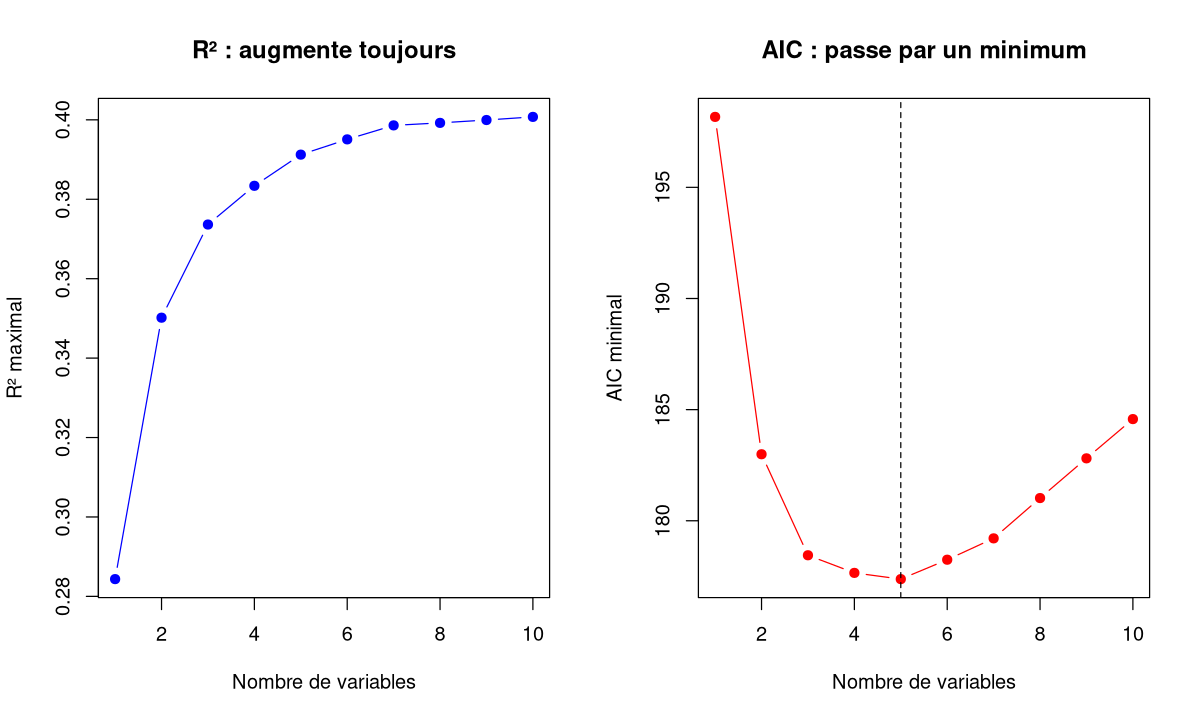

In [11]:
# Visualisation : meilleur R² et meilleur AIC pour chaque taille de modèle
best_r2  <- tapply(table$rsquare, table$n, max)
best_aic <- tapply(table$aic, table$n, min)
par(mfrow = c(1, 2))
plot(1:10, best_r2, type = "b", pch = 19, col = "blue",
     xlab = "Nombre de variables", ylab = "R² maximal", main = "R² : augmente toujours")
plot(1:10, best_aic, type = "b", pch = 19, col = "red",
     xlab = "Nombre de variables", ylab = "AIC minimal", main = "AIC : passe par un minimum")
abline(v = which.min(best_aic), lty = 2)
par(mfrow = c(1, 1))

> **Fonction R** : `olsrr::ols_step_all_possible(model, ...)`
>
> | Argument | Rôle |
> |---|---|
> | `model` | un objet `lm` contenant **toutes** les variables candidates |
>
> Renvoie un objet de classe `ols_step_all_possible` ; les indicateurs sont dans `$result` (un data frame, une ligne par modèle). `plot(selection)` trace les critères en fonction du nombre de variables.
>
> **Généralisation** : avec $p$ variables → $2^p - 1$ modèles. Faisable jusqu'à ~15-20 variables ; au-delà, le temps de calcul explose (10 variables = 1023 modèles, 20 variables = plus d'un million).

### Exercice 4.3 : explorer la table des 1023 modèles

1. Quel est le meilleur modèle selon le **R² ajusté** (`adjr`) ? Combien de variables contient-il ?
2. Quel est le meilleur modèle **à 3 variables** selon l'AIC ?
3. Retrouve dans `table` la ligne du modèle `x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]` (on en aura besoin pour la section 4.5).

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
# 1. Meilleur R² ajusté
table[which.max(table$adjr), ]

# 2. Meilleur modèle à 3 variables selon l'AIC
t3 <- table[table$n == 3, ]
t3[which.min(t3$aic), ]

# 3. Recherche d'un modèle précis
table[table$predictors == "x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]", ]
```

1. Le meilleur R² ajusté (0.3739) est atteint par un modèle à **6 variables** (`x[,1] x[,2] x[,4] x[,7] x[,8] x[,10]`), à peine au-dessus du meilleur modèle AIC à 5 variables (0.3735). Le R² ajusté pénalise les variables inutiles, mais **moins sévèrement que l'AIC** : il tolère ici une variable de plus. Les deux critères ne désignent donc pas toujours le même modèle.
2. Le meilleur modèle à 3 variables est `x[, 8] x[, 9] x[, 10]` (AIC 178.4).
   On filtre d'abord sur `n == 3` puis on prend le minimum de l'AIC.
3. Attention à l'écriture exacte de `predictors` : `"x[, 6]"` avec une **espace** après la virgule. Ce modèle a R² = 0.389 et AIC = 178.0.

</details>

## 4.4 Les critères de choix : R², R² ajusté, AIC, BIC

| Critère | Formule (idée) | Meilleur modèle | Pénalise la complexité ? |
|---|---|---|---|
| R² | $1 - \dfrac{SCE_{res}}{SCE_{tot}}$ | le **plus haut** | non : augmente **toujours** quand on ajoute une variable |
| R² ajusté | $1 - \dfrac{(1-R^2)(n-1)}{n-k-1}$ | le **plus haut** | oui (via $k$) |
| AIC (Akaike) | $-2\ln L + 2k$ | le **plus bas** | oui ($+2$ par paramètre) |
| BIC / SBC (Schwarz) | $-2\ln L + k\ln n$ | le **plus bas** | oui, plus sévère que l'AIC dès que $n \ge 8$ |

où $L$ est la vraisemblance du modèle, $k$ le nombre de paramètres estimés et $n$ le nombre d'observations.

> **AIC (Akaike Information Criterion)** : compromis entre **qualité d'ajustement** (terme $-2\ln L$, qui diminue quand le modèle colle mieux aux données) et **complexité** (terme $2k$). Il n'a pas de sens dans l'absolu : il sert à **comparer** des modèles ajustés **sur la même variable réponse et les mêmes données**. Les critères AIC et BIC seront détaillés au **module 3** du cours.

> **Complément : pourquoi deux AIC différents ?** Pour un modèle linéaire gaussien, $-2\ln L = n\ln(SCE_{res}/n) + \text{constante}$.
> - `AIC()` et `olsrr` utilisent la **log-vraisemblance complète** (avec la constante) → valeurs positives ici (≈ 178) ;
> - `stepAIC()` utilise `extractAIC()` = $n\ln(SCE_{res}/n) + 2k$, **sans la constante** → valeurs négatives ici (≈ −329).
>
> La différence est la même pour tous les modèles ajustés sur la même réponse : **le classement est identique**. Ne compare jamais un AIC de `stepAIC` avec un AIC d'`olsrr` !

In [13]:
# Vérification sur le modèle x6..x10
m510 <- lm(log10(y) ~ x[, 6] + x[, 7] + x[, 8] + x[, 9] + x[, 10])
AIC(m510)          # log-vraisemblance complète (comme olsrr)
extractAIC(m510)   # (nombre de paramètres, AIC "sans constante") comme stepAIC
n <- length(y); k <- 6                                         # 5 pentes + intercept
n * log(sum(resid(m510)^2) / n) + 2 * k                        # recalcul à la main de extractAIC
BIC(m510)

[1] 178.0031

[1]    6.0000 -329.1391

[1] -329.1391

[1] 200.2756

### Exercice 4.4 : vrai ou faux ?

1. Entre deux modèles, celui avec le plus grand R² est toujours le meilleur.
2. Un AIC de −329 est meilleur qu'un AIC de 178, quel que soit le modèle.
3. Le BIC a tendance à sélectionner des modèles avec moins de variables que l'AIC.
4. On peut comparer l'AIC d'un modèle sur `y` avec l'AIC d'un modèle sur `log10(y)`.

<details>
<summary><b>Voir la solution</b></summary>

1. **Faux** : le R² augmente mécaniquement avec le nombre de variables (overfitting) ; il ne sert à comparer que des modèles de **même taille**.
2. **Faux** : ces deux valeurs ne sont pas calculées de la même façon (`extractAIC` vs `AIC`) ; on ne compare que des AIC calculés de la même façon, sur les mêmes données.
3. **Vrai** : sa pénalité par paramètre est $\ln(n)$ (≈ 5.2 pour n = 178) au lieu de 2.
4. **Faux** : l'AIC dépend de l'échelle de la réponse ; il faut la **même variable réponse**.

</details>

## 4.5 Sélection backward (élimination descendante)

Il existe 3 méthodes courantes pour sélectionner les variables pas à pas (résolution §7.2) :

- **forward** : ajoute les variables une par une et vérifie que chaque ajout améliore le modèle ;
- **backward** : retire une par une la variable la moins informative ;
- **stepwise** : mélange des deux.

Dans R, on les réalise avec `stepAIC()` du package `MASS` ; le critère utilisé est l'**AIC**.

> **Backward** (syllabus §3.3) : on part de **toutes** les variables explicatives. Puis, itérativement, on retire **une par une** la variable la moins utile (celle dont le retrait diminue le plus l'AIC, ce qui correspond en pratique à la p-value la plus élevée). On s'arrête quand plus aucun retrait ne fait baisser l'AIC (ou quand le gain de R² devient trop faible).
>
> La méthode backward **n'est pas faisable si le nombre de variables explicatives est très grand** (il faut pouvoir ajuster le modèle complet, donc $n > p$).

In [14]:
backward <- stepAIC(lm(fmla), direction = "backward")   # trace affichée : une étape par itération

Start:  AIC=-322.57
log10(y) ~ x[, 1] + x[, 2] + x[, 3] + x[, 4] + x[, 5] + x[, 6] + 
    x[, 7] + x[, 8] + x[, 9] + x[, 10]



          Df Sum of Sq    RSS     AIC
- x[, 4]   1  0.033807 25.721 -324.33
- x[, 5]   1  0.043445 25.731 -324.27
- x[, 3]   1  0.057723 25.745 -324.17
- x[, 6]   1  0.090544 25.778 -323.94
- x[, 7]   1  0.096713 25.784 -323.90
- x[, 1]   1  0.141635 25.829 -323.59
- x[, 8]   1  0.155365 25.843 -323.49
- x[, 9]   1  0.181639 25.869 -323.31
- x[, 2]   1  0.198140 25.886 -323.20
- x[, 10]  1  0.213137 25.901 -323.10
<none>                 25.688 -322.57



Step:  AIC=-324.33
log10(y) ~ x[, 1] + x[, 2] + x[, 3] + x[, 5] + x[, 6] + x[, 7] + 
    x[, 8] + x[, 9] + x[, 10]



          Df Sum of Sq    RSS     AIC
- x[, 5]   1   0.03084 25.752 -326.12
- x[, 3]   1   0.03256 25.754 -326.11
- x[, 6]   1   0.05792 25.779 -325.93
- x[, 8]   1   0.13069 25.852 -325.43
- x[, 1]   1   0.13250 25.854 -325.42
- x[, 2]   1   0.24448 25.966 -324.65
- x[, 10]  1   0.27448 25.996 -324.44
<none>                 25.721 -324.33
- x[, 9]   1   0.39610 26.118 -323.61
- x[, 7]   1   0.41414 26.136 -323.49



Step:  AIC=-326.12
log10(y) ~ x[, 1] + x[, 2] + x[, 3] + x[, 6] + x[, 7] + x[, 8] + 
    x[, 9] + x[, 10]



...

          Df Sum of Sq    RSS     AIC
- x[, 1]   1   0.15997 25.939 -328.83
- x[, 6]   1   0.23947 26.019 -328.29
- x[, 2]   1   0.25673 26.036 -328.17
<none>                 25.779 -327.93
- x[, 7]   1   0.43322 26.213 -326.97
- x[, 8]   1   0.43828 26.218 -326.93
- x[, 9]   1   0.52567 26.305 -326.34
- x[, 10]  1   0.57554 26.355 -326.00



Step:  AIC=-328.83
log10(y) ~ x[, 2] + x[, 6] + x[, 7] + x[, 8] + x[, 9] + x[, 10]



          Df Sum of Sq    RSS     AIC
- x[, 2]   1   0.24792 26.187 -329.14
- x[, 6]   1   0.27992 26.219 -328.92
<none>                 25.939 -328.83
- x[, 7]   1   0.49086 26.430 -327.50
- x[, 8]   1   0.50218 26.442 -327.42
- x[, 9]   1   0.59538 26.535 -326.79
- x[, 10]  1   0.65355 26.593 -326.40



Step:  AIC=-329.14
log10(y) ~ x[, 6] + x[, 7] + x[, 8] + x[, 9] + x[, 10]



          Df Sum of Sq    RSS     AIC
<none>                 26.187 -329.14
- x[, 6]   1   0.49328 26.680 -327.82
- x[, 7]   1   0.62227 26.809 -326.96
- x[, 8]   1   0.78690 26.974 -325.87
- x[, 9]   1   0.80088 26.988 -325.78
- x[, 10]  1   0.93613 27.123 -324.89


### Lire la trace de `stepAIC`

Chaque bloc `Step:` correspond à une itération :

- `Start: AIC=-322.57` : AIC du modèle de départ (les 10 variables) ;
- le tableau liste chaque **action possible** : `- x[, 4]` = « retirer `x[, 4]` » ;
  - `Df` : nombre de paramètres retirés (1) ;
  - `Sum of Sq` : augmentation de la somme des carrés des résidus si on retire la variable (petite = variable peu utile) ;
  - `RSS` : somme des carrés des résidus (*Residual Sum of Squares*) du modèle après l'action ;
  - `AIC` : AIC du modèle après l'action ;
- `<none>` : ne rien faire ;
- les lignes sont **triées par AIC croissant** : l'algorithme choisit la **première** ligne. Si c'est `<none>`, l'algorithme s'arrête.

Ici : à la 1re itération, retirer `x[, 4]` fait passer l'AIC de −322.57 à −324.33 → on le retire. Puis `x[, 5]`, `x[, 3]`, `x[, 1]`, `x[, 2]`… Au dernier `Step` (AIC = −329.14), `<none>` est en tête : tout retrait **augmenterait** l'AIC → arrêt. On compte **6 itérations**.

In [15]:
summary(backward)


Call:
lm(formula = log10(y) ~ x[, 6] + x[, 7] + x[, 8] + x[, 9] + x[, 
    10])

Residuals:
     Min       1Q   Median       3Q      Max 
-1.05215 -0.25782 -0.00552  0.26017  0.90840 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)    1.6097     0.3867   4.162 4.97e-05 ***
x[, 6]       115.0544    63.9203   1.800   0.0736 .  
x[, 7]        42.9390    21.2394   2.022   0.0448 *  
x[, 8]      -320.4710   140.9641  -2.273   0.0242 *  
x[, 9]      -183.4000    79.9643  -2.294   0.0230 *  
x[, 10]      344.9858   139.1280   2.480   0.0141 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3902 on 172 degrees of freedom
Multiple R-squared:  0.3891,	Adjusted R-squared:  0.3713 
F-statistic: 21.91 on 5 and 172 DF,  p-value: < 2.2e-16


**Résultat** (identique à la résolution) : le modèle final contient **5 variables + l'intercept** : `x[,6] x[,7] x[,8] x[,9] x[,10]` (V715, V711, V714, V712, V713), avec **R² = 0.39**. Contrairement au modèle complet, presque tous les coefficients sont maintenant significatifs (p < 0.05, sauf `x[,6]` à 0.074).

On retrouve ce modèle dans la table des 1023 combinaisons :

In [16]:
table[table$predictors == "x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]", ]

,n,predictors,rsquare,adjr,aic
,<int>,<chr>,<dbl>,<dbl>,<dbl>
390,5,"x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]",0.3890871,0.371328,178.0031


Son AIC (178.0) est **légèrement moins bon** que celui du meilleur modèle trouvé par la recherche exhaustive (177.4) : la méthode backward est **rapide mais ne garantit pas** de trouver le meilleur sous-ensemble, car elle ne revient jamais sur une variable retirée.

> **Fonction R** : `MASS::stepAIC(object, scope, direction, trace, k = 2, steps = 1000)`
>
> | Argument | Rôle |
> |---|---|
> | `object` | modèle **de départ** (`lm`) : complet pour backward, vide (`~1`) pour forward |
> | `direction` | `"backward"`, `"forward"` ou `"both"` (= stepwise) |
> | `scope` | `list(upper = modèle_max, lower = modèle_min)` : l'espace de recherche (obligatoire pour forward) |
> | `trace` | `1` (défaut) affiche chaque étape ; `0` = silencieux |
> | `k` | pénalité par paramètre : `2` = AIC ; `log(n)` = **BIC** |
>
> Renvoie le **modèle `lm` final** (on peut donc faire `summary()`, `plot()`, `predict()`… dessus) ; `$anova` résume le chemin suivi.

In [17]:
backward$anova    # résumé compact du chemin suivi (une ligne par variable retirée)

Step,Df,Deviance,Resid. Df,Resid. Dev,AIC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
,NA,NA,167,25.68765,-322.5677
"- x[, 4]",1,0.03380666,168,25.72145,-324.3336
"- x[, 5]",1,0.03084183,169,25.75230,-326.1202
"- x[, 3]",1,0.02704648,170,25.77934,-327.9334
"- x[, 1]",1,0.15997217,171,25.93931,-328.8322
"- x[, 2]",1,0.24791974,172,26.18723,-329.1391


### Exercice 4.5 : backward avec le BIC

Refais une sélection backward en utilisant le **BIC** au lieu de l'AIC (indice : argument `k`), **sans afficher la trace**. Combien de variables sont conservées ? Compare au résultat avec l'AIC.

In [18]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
backward_bic <- stepAIC(lm(fmla), direction = "backward", k = log(length(y)), trace = 0)
formula(backward_bic)
summary(backward_bic)$r.squared
```

Avec `k = log(n)` (≈ 5.18), chaque paramètre coûte plus cher : le BIC ne conserve ici que **3 variables** (`x[,8] x[,9] x[,10]`, R² = 0.374) contre 5 avec l'AIC (R² = 0.389). Le modèle est plus parcimonieux, avec un R² un peu plus faible.

</details>

## 4.6 Sélection forward (ajout progressif)

> **Forward** (syllabus §3.3) : on part du modèle **vide** (intercept seul) et on **ajoute les variables une par une**, en prenant à chaque tour celle qui apporte le plus d'information (meilleur gain d'AIC, i.e. plus forte hausse du R²). On s'arrête quand aucun ajout n'améliore le modèle.

Il faut préciser à `stepAIC` l'espace de recherche via `scope` : le modèle minimal (`lower`) et le modèle maximal (`upper`).

### Une erreur à éviter (présente dans la résolution)

Dans la résolution 2024-2025 on trouve :

```r
model1 <- lm(fmla)     # log10(y) ~ x[,1] + ... + x[,10]
model2 <- lm(y ~ 1)    # y BRUT !
forward <- stepAIC(model2, direction = "forward", scope = list(upper = model1, lower = model2))
```

Le modèle de départ `model2` est construit sur **y brut**, alors que la formule complète utilise **log10(y)**. `stepAIC` garde la réponse du modèle de départ : la sélection forward/stepwise de la résolution est donc faite **sur la lactoferrine non transformée** (c'est pour cela que ses RSS valent des millions et que son AIC démarre à 2033.55, alors que celui du backward est d'environ −322). Ses résultats (4 variables `x[,10] x[,3] x[,7] x[,5]`, R² = 0.35) **ne sont pas comparables** au backward (réponse log10).

Reproduisons d'abord la version de la résolution (sans trace), puis la **version corrigée**.

In [19]:
# Version de la résolution (réponse = y brut, à ne pas reproduire)
model1 <- lm(fmla)
model2_brut <- lm(y ~ 1)
forward_resol <- stepAIC(model2_brut, direction = "forward",
                         scope = list(upper = model1, lower = model2_brut), trace = 0)
formula(forward_resol)
summary(forward_resol)$r.squared

y ~ x[, 10] + x[, 3] + x[, 7] + x[, 5]

[1] 0.3502268

In [20]:
# Version CORRIGÉE : le modèle de départ utilise aussi log10(y)
model2 <- lm(log10(y) ~ 1)
forward <- stepAIC(model2, direction = "forward",
                   scope = list(upper = model1, lower = model2))

Start:  AIC=-251.42
log10(y) ~ 1



          Df Sum of Sq    RSS     AIC
+ x[, 9]   1   12.1889 30.677 -308.97
+ x[, 10]  1   12.1745 30.691 -308.89
+ x[, 8]   1    9.7122 33.154 -295.15
+ x[, 7]   1    9.4098 33.456 -293.54
+ x[, 6]   1    5.8056 37.060 -275.32
+ x[, 4]   1    4.7561 38.110 -270.35
+ x[, 5]   1    3.4109 39.455 -264.18
+ x[, 2]   1    3.2493 39.616 -263.45
+ x[, 3]   1    2.9940 39.872 -262.31
+ x[, 1]   1    2.4522 40.414 -259.91
<none>                 42.866 -251.42



Step:  AIC=-308.97
log10(y) ~ x[, 9]



          Df Sum of Sq    RSS     AIC
+ x[, 4]   1   1.89309 28.784 -318.31
+ x[, 7]   1   1.75054 28.926 -317.43
+ x[, 2]   1   1.68303 28.994 -317.02
+ x[, 3]   1   1.14966 29.527 -313.77
+ x[, 6]   1   0.93125 29.746 -312.46
+ x[, 1]   1   0.46974 30.207 -309.72
<none>                 30.677 -308.97
+ x[, 8]   1   0.33976 30.337 -308.96
+ x[, 10]  1   0.05939 30.617 -307.32
+ x[, 5]   1   0.02054 30.656 -307.09



Step:  AIC=-318.31
log10(y) ~ x[, 9] + x[, 4]



...

          Df Sum of Sq    RSS     AIC
+ x[, 7]   1   0.79059 26.602 -328.34
+ x[, 2]   1   0.53406 26.859 -326.63
+ x[, 10]  1   0.45526 26.938 -326.11
<none>                 27.393 -325.13
+ x[, 1]   1   0.26910 27.124 -324.89
+ x[, 8]   1   0.15598 27.237 -324.14
+ x[, 5]   1   0.09462 27.298 -323.74
+ x[, 3]   1   0.00093 27.392 -323.13



Step:  AIC=-328.34
log10(y) ~ x[, 9] + x[, 4] + x[, 6] + x[, 7]



          Df Sum of Sq    RSS     AIC
+ x[, 2]   1   0.45274 26.149 -329.40
<none>                 26.602 -328.34
+ x[, 1]   1   0.16436 26.438 -327.44
+ x[, 3]   1   0.13474 26.467 -327.24
+ x[, 5]   1   0.08969 26.512 -326.94
+ x[, 8]   1   0.08744 26.515 -326.93
+ x[, 10]  1   0.03102 26.571 -326.55



Step:  AIC=-329.4
log10(y) ~ x[, 9] + x[, 4] + x[, 6] + x[, 7] + x[, 2]



          Df Sum of Sq    RSS     AIC
<none>                 26.149 -329.40
+ x[, 1]   1  0.163075 25.986 -328.51
+ x[, 5]   1  0.060296 26.089 -327.81
+ x[, 3]   1  0.046814 26.103 -327.72
+ x[, 8]   1  0.026179 26.123 -327.57
+ x[, 10]  1  0.005950 26.143 -327.44


**Lecture de la trace** : à la première étape, l'algorithme teste le modèle « intercept + 1 variable » pour chacune des 10 variables (lignes `+ x[, j]`). La meilleure (AIC le plus bas) est ajoutée, puis on recommence avec les variables restantes, jusqu'à ce que `<none>` soit en tête.

In [21]:
summary(forward)
table[table$predictors == "x[, 2] x[, 4] x[, 6] x[, 7] x[, 9]", ]   # même modèle dans la recherche exhaustive


Call:
lm(formula = log10(y) ~ x[, 9] + x[, 4] + x[, 6] + x[, 7] + x[, 
    2])

Residuals:
     Min       1Q   Median       3Q      Max 
-1.06150 -0.26058 -0.00593  0.27584  0.95028 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   1.7568     0.3714   4.730 4.65e-06 ***
x[, 9]       46.6171    16.9187   2.755 0.006494 ** 
x[, 4]       21.6662    11.6789   1.855 0.065284 .  
x[, 6]      -15.9288     4.5661  -3.489 0.000617 ***
x[, 7]      -56.1019    25.9739  -2.160 0.032162 *  
x[, 2]       -1.1531     0.6682  -1.726 0.086204 .  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3899 on 172 degrees of freedom
Multiple R-squared:   0.39,	Adjusted R-squared:  0.3722 
F-statistic: 21.99 on 5 and 172 DF,  p-value: < 2.2e-16


,n,predictors,rsquare,adjr,aic
,<int>,<chr>,<dbl>,<dbl>,<dbl>
388,5,"x[, 2] x[, 4] x[, 6] x[, 7] x[, 9]",0.3899696,0.3722361,177.7457


Avec la réponse correcte (log10), la sélection forward retient **5 variables** (`x[,9] x[,4] x[,6] x[,7] x[,2]`), R² = 0.390 et AIC (olsrr) = 177.7 : c'est le **4e meilleur** modèle de la recherche exhaustive. Le modèle diffère de celui du backward : **les méthodes pas-à-pas ne convergent pas forcément vers le même sous-ensemble**, surtout quand les variables sont colinéaires (plusieurs combinaisons donnent quasiment la même information).

> **Attention** : dans `scope`, `upper` et `lower` doivent avoir **la même réponse** que le modèle de départ. Vérifie toujours la première ligne de la trace (`Start: AIC=... log10(y) ~ 1`).

## 4.7 Sélection stepwise (pas à pas mixte)

> **Stepwise** (syllabus §3.3) : combine les deux méthodes. Les variables sont ajoutées une par une, mais à chaque tour on vérifie aussi que **toutes les variables déjà présentes restent utiles** (p-value < 5 ou 10 % selon le seuil souhaité, ou ici : retrait qui ferait baisser l'AIC). Une variable entrée tôt peut donc ressortir plus tard.
>
> D'après le syllabus, c'est **la méthode la plus efficace mais la plus longue** en temps de calcul.

Dans `stepAIC`, c'est `direction = "both"` : à chaque étape la trace propose des lignes `+` (ajouts) **et** `-` (retraits).

In [22]:
stepwise <- stepAIC(model2, direction = "both",
                    scope = list(upper = model1, lower = model2), trace = 0)
summary(stepwise)
stepwise$anova      # chemin : uniquement des ajouts ici


Call:
lm(formula = log10(y) ~ x[, 9] + x[, 4] + x[, 6] + x[, 7] + x[, 
    2])

Residuals:
     Min       1Q   Median       3Q      Max 
-1.06150 -0.26058 -0.00593  0.27584  0.95028 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   1.7568     0.3714   4.730 4.65e-06 ***
x[, 9]       46.6171    16.9187   2.755 0.006494 ** 
x[, 4]       21.6662    11.6789   1.855 0.065284 .  
x[, 6]      -15.9288     4.5661  -3.489 0.000617 ***
x[, 7]      -56.1019    25.9739  -2.160 0.032162 *  
x[, 2]       -1.1531     0.6682  -1.726 0.086204 .  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3899 on 172 degrees of freedom
Multiple R-squared:   0.39,	Adjusted R-squared:  0.3722 
F-statistic: 21.99 on 5 and 172 DF,  p-value: < 2.2e-16


Step,Df,Deviance,Resid. Df,Resid. Dev,AIC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
,NA,NA,177,42.86574,-251.4205
"+ x[, 9]",1,12.1889392,176,30.67680,-308.9733
"+ x[, 4]",1,1.8930915,175,28.78371,-318.3114
"+ x[, 6]",1,1.3909727,174,27.39273,-325.1280
"+ x[, 7]",1,0.7905950,173,26.60214,-328.3410
"+ x[, 2]",1,0.4527352,172,26.14940,-329.3964


Ici, le stepwise donne **le même modèle que le forward** (aucune variable n'a été retirée en cours de route), exactement comme dans la résolution (où forward et stepwise donnaient aussi le même modèle, mais sur y brut).

> **Complément** : `direction = "both"` peut aussi partir du modèle **complet** : `stepAIC(lm(fmla), direction = "both")`. Il fait alors du backward en s'autorisant à ré-ajouter des variables retirées.

### Exercice 4.6 : stepwise depuis le modèle complet

Lance un stepwise (`direction = "both"`) en partant du **modèle complet** `lm(fmla)`, sans trace. Obtiens-tu le modèle du backward ou celui du forward ? Affiche le chemin suivi avec `$anova`.

In [23]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
step_full <- stepAIC(lm(fmla), direction = "both",
                     scope = list(upper = model1, lower = model2), trace = 0)
formula(step_full)
step_full$anova
```

En partant du modèle complet, l'algorithme commence par retirer des variables (comme le backward) et, ici, aboutit au même modèle que le backward (`x[,6]` à `x[,10]`). **Le point de départ influence le résultat** : c'est une limite des méthodes pas-à-pas.

</details>

### Exercice 4.7 : reproduire la sélection de la résolution sur y brut

La résolution utilisait `y` brut pour le forward. Fais une sélection **backward sur y brut** (formule `y ~ x[,1] + ... + x[,10]`, sans trace) et compare au forward de la résolution (`forward_resol`). Pourquoi a-t-on choisi log10(y) dans le cours ?

In [24]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
fmla_brut <- as.formula(paste("y ~", paste(xnam, collapse = "+")))
backward_brut <- stepAIC(lm(fmla_brut), direction = "backward", trace = 0)
formula(backward_brut); summary(backward_brut)$r.squared
formula(forward_resol); summary(forward_resol)$r.squared
shapiro.test(resid(backward_brut))
```

Sur y brut, le backward retient 7 variables (`x[,3] x[,5] x[,6] x[,7] x[,8] x[,9] x[,10]`, R² = 0.377) et le forward de la résolution 4 : les méthodes ne s'accordent pas. Surtout, **les résidus ne sont pas normaux** (Shapiro p ≪ 0.05, comme pour `reg1` et `reg2`) : les tests de significativité et l'AIC (qui suppose des erreurs gaussiennes) ne sont alors pas fiables. C'est pourquoi on travaille sur **log10(y)**, qui rend les résidus normaux.

</details>

## 4.8 Comparaison des méthodes et commentaires finaux

In [25]:
# Tableau comparatif des modèles retenus (réponse log10(y))
best_exh <- lm(log10(y) ~ x[, 2] + x[, 4] + x[, 7] + x[, 8] + x[, 10])   # meilleur AIC exhaustif
modeles <- list(complet = model1, exhaustif_AIC = best_exh,
                backward = backward, forward = forward, stepwise = stepwise)
comp <- t(sapply(modeles, function(m) c(
  k      = length(coef(m)) - 1,
  R2     = summary(m)$r.squared,
  adjR2  = summary(m)$adj.r.squared,
  RMSE   = sqrt(sum(resid(m)^2) / m$df.residual),
  AIC    = AIC(m))))
kable(comp, digits = 3)



|              |  k|    R2| adjR2|  RMSE|     AIC|
|:-------------|--:|-----:|-----:|-----:|-------:|
|complet       | 10| 0.401| 0.365| 0.392| 184.574|
|exhaustif_AIC |  5| 0.391| 0.374| 0.390| 177.376|
|backward      |  5| 0.389| 0.371| 0.390| 178.003|
|forward       |  5| 0.390| 0.372| 0.390| 177.746|
|stepwise      |  5| 0.390| 0.372| 0.390| 177.746|

**Conclusions (résolution §7.6, syllabus §3.3)** :

- La sélection a été **plus efficace en testant toutes les combinaisons** de features (meilleur AIC), mais ce processus **prend plus de temps** et devient impossible quand le nombre de variables augmente.
- Les sélections **stepwise, forward et backward** sont beaucoup plus rapides. Trouver le meilleur sous-ensemble de variables est **toujours un compromis** (temps de calcul vs optimalité).
- La méthode **backward** n'est pas faisable si le nombre de variables est très grand (> n). La méthode **stepwise** est la plus efficace des trois mais demande le plus de calcul.
- Avec des variables **colinéaires**, plusieurs sous-ensembles différents donnent quasiment les mêmes performances (R² entre 0.389 et 0.391) : il ne faut pas sur-interpréter le choix d'une variable plutôt qu'une voisine.
- D'autres algorithmes de sélection existent en Data Mining (**RFE** – *Recursive Feature Elimination*, **algorithmes génétiques**) mais sont **hors du cadre de ce cours**.
- Le nombre de features de départ a été fixé à **10** (les plus corrélées). On pourrait l'augmenter pour améliorer le modèle, mais vu les **fortes corrélations entre points spectraux adjacents**, des méthodes qui **réduisent la dimension** de la matrice X (PCR, PLS) sont plus pertinentes : elles seront vues au **module 2**. Les régressions pénalisées (Lasso, partie 6) sont une autre réponse.

### Exercice 4.8 (QCM) : choisir une méthode

Pour chaque situation, quelle méthode de sélection choisirais-tu ?

a) 8 variables candidates, n = 200, temps de calcul sans importance.
b) 60 variables candidates, n = 40.
c) 40 variables candidates, n = 500, on veut vérifier à chaque étape que les variables entrées restent utiles.

<details>
<summary><b>Voir la solution</b></summary>

a) **Toutes les combinaisons** (`ols_step_all_possible`) : $2^8 - 1 = 255$ modèles, rapide, et on est sûr de trouver le meilleur sous-ensemble selon le critère choisi.

b) **Pas de backward** (le modèle complet n'est pas estimable car p > n : coefficients `NA`). Forward/stepwise depuis le modèle vide, ou mieux : une régression pénalisée (Lasso, partie 6) ou une réduction de dimension (PLS, module 2).

c) **Stepwise** (`direction = "both"`) : 2^40 combinaisons, c'est trop pour la recherche exhaustive ; le stepwise ré-évalue les variables déjà entrées.

</details>

## 4.9 Outils d'interprétation : importance relative des variables

Pour mieux **interpréter** les coefficients d'une régression, on peut calculer la **contribution** de chaque variable au R². Avec des variables corrélées, cette contribution dépend de **l'ordre** dans lequel les variables entrent dans le modèle. Plusieurs méthodes existent (résolution §8) :

| Méthode | Principe |
|---|---|
| **lmg** | contribution **moyenne** d'une variable en faisant varier **l'ordre** des variables explicatives dans la régression (Chevan & Sutherland, 1991 ; Lindeman, Merenda & Gold) |
| **last** | contribution d'une variable quand elle est ajoutée **en dernier** dans le modèle (gain de R² quand on l'ajoute à toutes les autres) |
| **first** | contribution d'une variable quand elle est ajoutée **en premier** (= son r² univarié avec y) |
| **pratt** | **produit** du coefficient standardisé et de la corrélation (peut être négatif !) |

Elles se calculent avec `calc.relimp()` du package `relaimpo`. Comme dans la résolution, on l'applique au meilleur modèle de la sélection exhaustive (5 variables).

> **Attention** : la résolution ajuste ce modèle sur **y brut** (`lm(y ~ ...)`) et non sur log10(y). On reproduit ce choix pour retrouver ses chiffres (R² = 0.36), puis tu le referas sur log10(y) en exercice.

In [26]:
regcontri <- lm(y ~ x[, 2] + x[, 4] + x[, 7] + x[, 8] + x[, 10])
summary(regcontri)


Call:
lm(formula = y ~ x[, 2] + x[, 4] + x[, 7] + x[, 8] + x[, 10])

Residuals:
    Min      1Q  Median      3Q     Max 
-508.91  -83.92  -31.90   45.04 1447.23 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)     96.83     234.57   0.413 0.680261    
x[, 2]        -323.78     421.00  -0.769 0.442909    
x[, 4]       11656.28    5904.10   1.974 0.049952 *  
x[, 7]      -24287.85   10719.76  -2.266 0.024716 *  
x[, 8]      -30392.12    8788.60  -3.458 0.000686 ***
x[, 10]      40819.69   12516.60   3.261 0.001338 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 245.3 on 172 degrees of freedom
Multiple R-squared:  0.3576,	Adjusted R-squared:  0.339 
F-statistic: 19.15 on 5 and 172 DF,  p-value: 3.988e-15


Response variable: y 
Total response variance: 91019.55 
Analysis based on 178 observations 

5 Regressors: 
x[, 2] x[, 4] x[, 7] x[, 8] x[, 10] 
Proportion of variance explained by model: 35.76%
Metrics are normalized to sum to 100% (rela=TRUE). 

Relative importance metrics: 

               lmg      last      first       pratt
x[, 2]  0.06181815 0.0183587 0.06358151  0.03283837
x[, 4]  0.13609151 0.1209840 0.11285548  1.63746618
x[, 7]  0.22709138 0.1593392 0.23646658 -5.10669756
x[, 8]  0.24288301 0.3711911 0.26393040 -3.53688980
x[, 10] 0.33211595 0.3301270 0.32316602  7.97328280

Average coefficients for different model sizes: 

               1X        2Xs        3Xs         4Xs         5Xs
x[, 2]  -1422.790 -1185.5520  -794.0217   -423.8248   -323.7803
x[, 4]   1823.273 -1540.9870 -3933.6063   -889.5300  11656.2817
x[, 7]   2552.466  2430.0465  4180.3259  -2079.1762 -24287.8496
x[, 8]   5147.190   990.3109 -5452.2000 -15129.4197 -30392.1193
x[, 10]  3754.909  6263.3549  8298.46

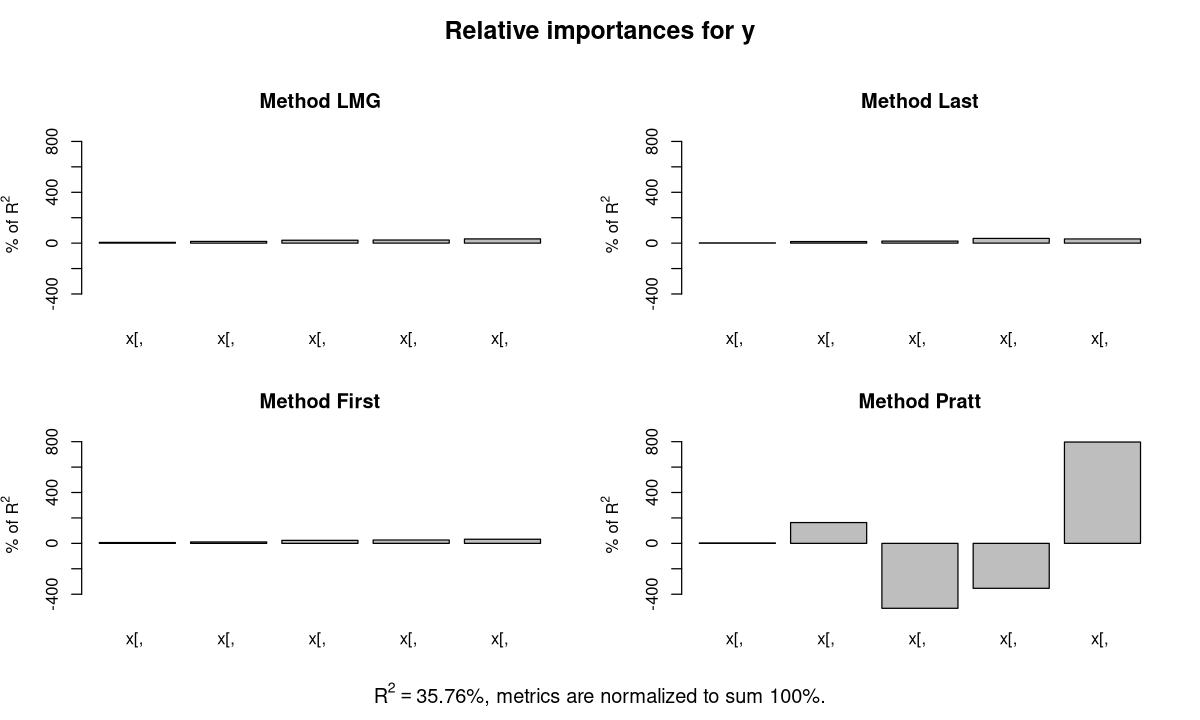

In [27]:
contribution <- calc.relimp(regcontri, type = c("lmg", "last", "first", "pratt"), rela = TRUE)
contribution
par(mfrow = c(1, 1))
plot(contribution)        # (la résolution écrit plot.relimplm(contribution), c'est la même méthode)

**Lecture** :

- `Proportion of variance explained by model: 35.76%` = R² du modèle ;
- `rela = TRUE` : les contributions sont **normalisées pour sommer à 100 %** (on répartit le R² entre les variables) ;
- **lmg** : `x[,10]` (V713) est la variable la plus importante (≈ 33 % du R² expliqué), puis `x[,8]` et `x[,7]` (≈ 23-24 %), `x[,2]` (V679) contribue peu (≈ 6 %) ;
- **pratt** donne des valeurs négatives et supérieures à 1 : c'est un signe typique de **colinéarité** (coefficients standardisés de signes opposés et très grands) → la méthode pratt est **difficilement interprétable** ici ;
- les coefficients changent fortement selon le nombre de variables du modèle (section `Average coefficients for different model sizes` de la sortie bootstrap ci-dessous) : encore la colinéarité.

### Estimer l'incertitude par bootstrap

Ces méthodes ne fournissent pas d'erreur standard. En créant de nombreux **sous-échantillons** du jeu de données, on peut en estimer une : c'est le **bootstrap** (expliqué en détail au **module 4**). Exemple avec 10 réplications seulement (comme la résolution ; en pratique on en prend ≥ 1000) :

In [28]:
set.seed(1)    # pour un résultat reproductible (le bootstrap est aléatoire)
regboot <- lm(y ~ x[, 2] + x[, 4] + x[, 7] + x[, 8] + x[, 10])
boot <- boot.relimp(regboot, b = 10, type = c("lmg", "last", "first", "pratt"),
                    rank = TRUE, diff = TRUE, rela = TRUE)
# Avec seulement 10 réplications, R émet des dizaines d'avertissements "extreme order statistics
# used as endpoints" (trop peu de réplications pour des IC fiables) : on les masque ici.
be <- suppressWarnings(booteval.relimp(boot))
print(be)

Response variable: y 
Total response variance: 91019.55 
Analysis based on 178 observations 

5 Regressors: 
x[, 2] x[, 4] x[, 7] x[, 8] x[, 10] 
Proportion of variance explained by model: 35.76%
Metrics are normalized to sum to 100% (rela=TRUE). 

Relative importance metrics: 

               lmg      last      first       pratt
x[, 2]  0.06181815 0.0183587 0.06358151  0.03283837
x[, 4]  0.13609151 0.1209840 0.11285548  1.63746618
x[, 7]  0.22709138 0.1593392 0.23646658 -5.10669756
x[, 8]  0.24288301 0.3711911 0.26393040 -3.53688980
x[, 10] 0.33211595 0.3301270 0.32316602  7.97328280

Average coefficients for different model sizes: 

               1X        2Xs        3Xs         4Xs         5Xs
x[, 2]  -1422.790 -1185.5520  -794.0217   -423.8248   -323.7803
x[, 4]   1823.273 -1540.9870 -3933.6063   -889.5300  11656.2817
x[, 7]   2552.466  2430.0465  4180.3259  -2079.1762 -24287.8496
x[, 8]   5147.190   990.3109 -5452.2000 -15129.4197 -30392.1193
x[, 10]  3754.909  6263.3549  8298.46

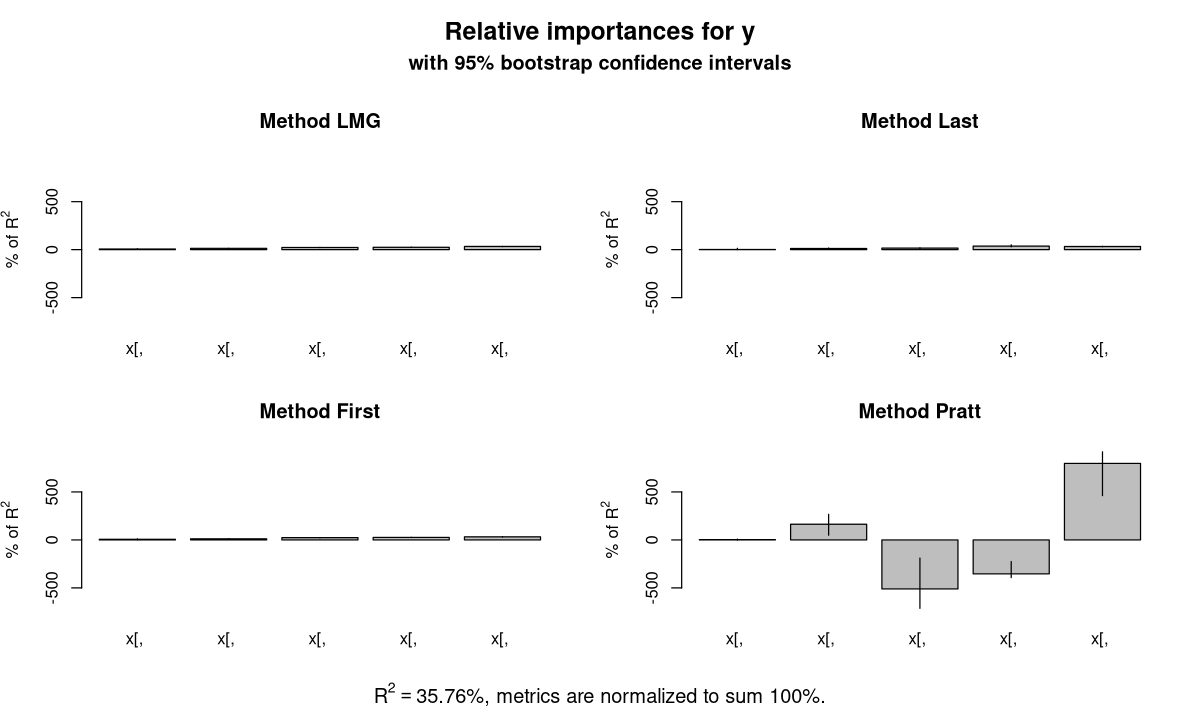

In [29]:
suppressWarnings(plot(booteval.relimp(boot, sort = FALSE)))   # barres = contributions, segments = IC à 95 %

**Lecture** :

- `Relative Contributions with confidence intervals` : pour chaque métrique, contribution, **lettres** = rangs couverts par l'intervalle de confiance bootstrap (`A____` = toujours 1re ; `___DE` = 4e ou 5e), puis bornes inférieure/supérieure à 95 % ;
- `Differences between Relative Contributions` : différence de contribution entre deux variables ; une `*` indique que l'IC de la différence **n'inclut pas 0** → les deux variables ont des contributions significativement différentes.
- Les résultats diffèrent légèrement de la résolution car le bootstrap est **aléatoire** (et seulement 10 réplications).

> **Fonctions R** du package `relaimpo`
>
> | Fonction | Rôle | Arguments principaux |
> |---|---|---|
> | `calc.relimp(model, type, rela)` | contributions relatives | `type` ∈ `"lmg"`, `"last"`, `"first"`, `"pratt"`, `"betasq"`, `"genizi"`, `"car"` ; `rela = TRUE` → normalise à 100 % |
> | `boot.relimp(model, b, type, rank, diff, rela)` | bootstrap des contributions | `b` = nombre de réplications ; `rank`/`diff` = IC des rangs / des différences |
> | `booteval.relimp(boot, sort, level)` | intervalles de confiance | `level = 0.95` par défaut |
> | `plot(...)` | graphiques en barres | sur un résultat de `calc.relimp` ou `booteval.relimp` |
>
> **Généralisation** : utilisable sur n'importe quel modèle `lm` avec au moins 2 variables explicatives. Le calcul de lmg devient long au-delà d'une quinzaine de variables ($2^p$ ordres partiels).

### Exercice 4.9 : importance relative sur log10(y)

1. Ajuste le modèle `log10(y) ~ x[,2] + x[,4] + x[,7] + x[,8] + x[,10]` (le meilleur modèle AIC, sur la bonne réponse).
2. Calcule les contributions relatives **lmg** et **first** (normalisées).
3. Vérifie que la contribution **first** non normalisée (`rela = FALSE`) de `x[,10]` est bien égale au r² de la régression univariée `lm(log10(y) ~ x[,10])`.

In [30]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
m_log <- lm(log10(y) ~ x[, 2] + x[, 4] + x[, 7] + x[, 8] + x[, 10])
calc.relimp(m_log, type = c("lmg", "first"), rela = TRUE)

# Vérification de "first" (non normalisé)
c_first <- calc.relimp(m_log, type = "first", rela = FALSE)
c_first@first
summary(lm(log10(y) ~ x[, 10]))$r.squared      # identique à la valeur de x[, 10]
```

La métrique **first** est simplement le R² de la régression **univariée** de y sur la variable : c'est la contribution de la variable quand elle est seule (ou ajoutée en premier). Les résultats sont accessibles par `@` car l'objet est de classe S4.

</details>

## 4.10 Compléments : `step()` et `leaps::regsubsets()`

Deux alternatives utiles (hors syllabus, mais fréquentes dans les scripts R) :

- `step()` (R de base, package `stats`) : même logique et mêmes arguments que `stepAIC()` (`direction`, `scope`, `k`, `trace`) ;
- `leaps::regsubsets()` : recherche du **meilleur sous-ensemble pour chaque taille** de modèle, beaucoup plus rapide qu'`ols_step_all_possible()` (algorithme *branch and bound*), utilisable avec plus de variables.

In [31]:
# step() de base R : même résultat que stepAIC backward
formula(step(lm(fmla), direction = "backward", trace = 0))

# regsubsets : meilleur modèle pour chaque taille (1 à 10 variables)
suppressPackageStartupMessages(library(leaps))
dat <- data.frame(ly = log10(y), x)          # les colonnes portent les noms V608, ..., V713
rs <- regsubsets(ly ~ ., data = dat, nvmax = 10)
rs_sum <- summary(rs)
data.frame(n = 1:10, R2 = round(rs_sum$rsq, 3), adjR2 = round(rs_sum$adjr2, 3),
           BIC = round(rs_sum$bic, 1))
coef(rs, which.max(rs_sum$adjr2))           # coefficients du meilleur modèle selon le R² ajusté

log10(y) ~ x[, 6] + x[, 7] + x[, 8] + x[, 9] + x[, 10]

n,R2,adjR2,BIC
<int>,<dbl>,<dbl>,<dbl>
1,0.284,0.280,-49.2
2,0.350,0.343,-61.2
3,0.374,0.363,-62.5
4,0.383,0.369,-60.2
5,0.391,0.374,-57.3
6,0.395,0.374,-53.2
7,0.399,0.374,-49.1
8,0.399,0.371,-44.1
9,0.400,0.368,-39.1


(Intercept)        V608        V679        V710        V711        V714 
  1.6960324  -0.1138808  -1.1175598  15.1452957 -31.3966924 -44.9342453 
       V713 
 57.5139031

## Récapitulatif

**Points clés**

- Avec beaucoup de variables **colinéaires**, un modèle complet a des coefficients instables et non significatifs → il faut **sélectionner** les variables (modèle **parcimonieux**).
- Pré-sélection par **corrélation** (simple, mais ignore les relations non linéaires et les redondances entre variables).
- **Toutes les combinaisons** ($2^p - 1$ modèles) : optimal mais coûteux → seulement pour peu de variables.
- **Backward** (tout → retrait), **Forward** (vide → ajout), **Stepwise** (ajout + vérification des variables présentes) : rapides, pas forcément optimaux, et **dépendants du point de départ**.
- Critères : **R²** (ne pénalise pas la complexité), **R² ajusté** (↑ = mieux), **AIC** et **BIC** (↓ = mieux, BIC plus sévère). On ne compare des AIC que sur **la même réponse**, calculés **de la même façon**.
- Vérifier que le modèle de départ et le `scope` de `stepAIC` utilisent **la même variable réponse** (erreur y vs log10(y) de la résolution).
- **Importance relative** (`relaimpo`) : lmg, last, first, pratt ; IC par **bootstrap** (module 4).
- Sur la lactoferrine : meilleur modèle à **5 features, R² ≈ 0.39** (vs 0.40 avec les 10) → pour aller plus loin : régressions pénalisées (partie 6), PCR/PLS (module 2).

**Fonctions R vues**

| Fonction | Package | Usage |
|---|---|---|
| `paste0()`, `paste(collapse=)` | base | générer des noms / coller des chaînes |
| `as.formula()` | stats | chaîne → formule |
| `ols_step_all_possible()` | olsrr | tous les sous-ensembles ; résultats dans `$result` |
| `order()`, `which.min()`, `tapply()` | base | trier / trouver le meilleur modèle |
| `stepAIC(object, scope, direction, k, trace)` | MASS | backward / forward / stepwise |
| `AIC()`, `BIC()`, `extractAIC()` | stats | critères d'information |
| `calc.relimp()`, `boot.relimp()`, `booteval.relimp()` | relaimpo | importance relative + bootstrap |
| `step()` | stats | équivalent de `stepAIC` |
| `regsubsets()` | leaps | meilleur sous-ensemble par taille |

**Partie suivante** : `05_Estimation_numerique_descente_de_gradient.ipynb` : comment estimer les coefficients **numériquement** (fonction de coût, descente de gradient).